# Stabilità carica e corrente nel tempo
1. **Carica vs tempo**: il file ROOT viene diviso in batch di eventi consecutivi (30000); per ogni batch si fitta `area_new` (Landau/Langaus) e si prende l'MPV (picco del fit) → carica = MPV / `CHARGE_DIV`.
2. **Corrente vs tempo**: dal file `.txt` si plotta la corrente dei quattro sensori.

Tagli `tmax` e `pmax`: scelti una volta sola (sull'intero file) e uguali per tutti i batch.


In [278]:
import uproot
import awkward as ak
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import moyal
from scipy.optimize import curve_fit
import os, glob, warnings
warnings.filterwarnings('ignore')

try:
    import mplhep as hep
except ImportError:
    hep = None
    print("mplhep non trovato: i plot nel tempo usano lo stile matplotlib standard")

matplotlib.rcParams.update({
    'font.family':     'Helvetica',
    'font.sans-serif': ['Helvetica', 'Arial', 'sans-serif'],
})

def _style_ax(ax):
    ax.set_facecolor('white')
    ax.grid(True, linestyle='--', linewidth=0.5, color='#cccccc', alpha=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


In [279]:
# ── File ─────────────────────────────────────────────────────────────────────
DATA_DIR     = "/Users/leonardolanteri/Desktop/PhD/Data+Plots+Macros/ETL/BETA 2026/FBK/Run0_PRE_LF-FBK_Current&Charge_Stabilty_neg25"
ROOT_FILE    = os.path.join(DATA_DIR, "stats_Sr_Run0_Ch0-550V_trig2750V.root")
CURRENT_FILE = os.path.join(DATA_DIR, "Sr_Run0_current.txt")
DATA_DIR_NEG18   = "/Users/leonardolanteri/Desktop/PhD/Data+Plots+Macros/ETL/BETA 2026/FBK/Run00_PRE_FBK_Current&Charge_Stabilty_neg18"
CURRENT_FILE_NEG18 = os.path.join(DATA_DIR_NEG18, "Sr_Run00_current_SYNTHETIC_target.txt")   # solo corrente (-18 °C)
DATA_DIR_NEG11   = "/Users/leonardolanteri/Desktop/PhD/Data+Plots+Macros/ETL/BETA 2026/FBK/Run000_PRE_FBK_Current&Charge_Stabilty_neg11"
CURRENT_FILE_NEG11 = os.path.join(DATA_DIR_NEG11, "Sr_Run000_current.txt")   # solo corrente (-11 °C)

# ── Canali ───────────────────────────────────────────────────────────────────
N_CHANNELS  = 2          # numero di canali attivi nel file ROOT
MCP_CHANNEL = 1          # indice del canale MCP (-1 se non presente)
HAS_MCP      = MCP_CHANNEL >= 0
DUT_CHANNELS = [ch for ch in range(N_CHANNELS) if ch != MCP_CHANNEL]

# ── Batch ────────────────────────────────────────────────────────────────────
BATCH_SIZE      = 30000   # eventi consecutivi per batch
HOURS_PER_BATCH = 2.0     # durata assunta di un batch [h]
TIME_MODE       = 'assumed'   # 'assumed' = HOURS_PER_BATCH per batch
                              # 'file'    = tempo reale dal branch `time` del ROOT
MIN_LAST_FRAC   = 0.9     # l'ultimo batch (incompleto) è tenuto se ha almeno questa frazione di BATCH_SIZE
MIN_EVENTS_FIT  = 500     # sotto questa soglia (dopo i tagli) il batch non viene fittato

# ── Origine dei tempi ────────────────────────────────────────────────────────
START_BATCH = 0           # batch che definisce t = 0: i plot (carica e corrente) partono da qui

# ── Sensori (indice = canale HV: I0..I3 nel file della corrente) ─────────────
# Il DUT del file ROOT (CH0) è il sensore sul canale HV 0 -> carica e corrente
SENSOR_LABELS = {
    0: "FBK-LF W16-TS18 1.5e15",   # corrente + carica
    1: "FBK-LF W16-TS9 1.5e15",    # solo corrente
    2: "FBK-LF W16-TS2 1e15",      # solo corrente
    3: "FBK-LF W16-TS25 1e15",     # solo corrente
}
CHARGE_SENSOR = 0         # canale HV del sensore di cui è misurata la carica

# ── Carica ───────────────────────────────────────────────────────────────────
CHARGE_DIV = 4.7          # carica [fC] = MPV area_new / CHARGE_DIV (1 = area grezza)

# ── Titoli / salvataggio ─────────────────────────────────────────────────────
TITLE    = "FBK LF — Stability"
SUBTITLE = r"Beta setup ($-25^\circ$C)"
SAVE_IMAGES = False       # True -> salva i plot nel tempo in SAVE_DIR
SAVE_DIR    = "Beta_images"


In [280]:
# ── Lettura file ROOT (una sola volta) ───────────────────────────────────────
with uproot.open(ROOT_FILE) as f:
    tree     = f["Analysis"]
    pmax_ak  = tree["pmax"].array(library="ak")
    tmax_ak  = tree["tmax"].array(library="ak")
    area_ak  = tree["area_new"].array(library="ak")
    time_arr = tree["time"].array(library="np").astype(float)

pmax_all = {ch: ak.to_numpy(pmax_ak[:, ch]).astype(float) for ch in range(N_CHANNELS)}
tmax_all = {ch: ak.to_numpy(tmax_ak[:, ch]).astype(float) for ch in DUT_CHANNELS}
area_all = {ch: ak.to_numpy(area_ak[:, ch]).astype(float) for ch in DUT_CHANNELS}

n_events = len(time_arr)
n_full   = n_events // BATCH_SIZE
rest     = n_events % BATCH_SIZE
keep_last = rest >= MIN_LAST_FRAC * BATCH_SIZE
n_batch  = n_full + (1 if keep_last else 0)
print(f"{n_events} eventi -> {n_batch} batch da {BATCH_SIZE}"
      f"{' (ultimo da ' + str(rest) + ' eventi)' if keep_last and rest else ''}"
      f"{' (scartati ' + str(rest) + ' eventi finali)' if rest and not keep_last else ''}")
print(f"Durata run (branch time): {(time_arr[-1]-time_arr[0])/3600:.2f} h"
      f"  ->  {BATCH_SIZE/n_events*(time_arr[-1]-time_arr[0])/3600:.2f} h per {BATCH_SIZE} eventi"
      f"  (assunto: {HOURS_PER_BATCH} h)")


929979 eventi -> 31 batch da 30000 (ultimo da 29979 eventi)
Durata run (branch time): 46.80 h  ->  1.51 h per 30000 eventi  (assunto: 2.0 h)


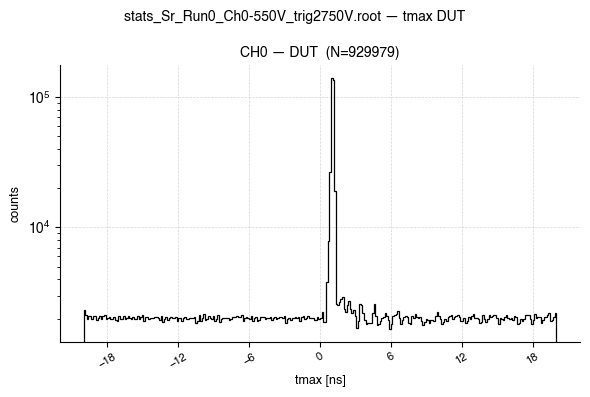

In [281]:
# ── tmax distribution per canali DUT (intero file, nessun taglio) ────────────
TMAX_BINS  = 300
TMAX_RANGE = None    # es. (0, 2)   range x di tmax [ns]; None = automatico

fig, axes = plt.subplots(1, len(DUT_CHANNELS), figsize=(6*len(DUT_CHANNELS), 4), squeeze=False)
fig.patch.set_facecolor('white')
fig.suptitle(f"{os.path.basename(ROOT_FILE)} — tmax DUT", fontsize=10, fontweight='bold')
for ax, ch in zip(axes[0], DUT_CHANNELS):
    tm = tmax_all[ch][np.isfinite(tmax_all[ch])]
    _style_ax(ax)
    ax.hist(tm, bins=TMAX_BINS, range=TMAX_RANGE, log=True, histtype='step',
            color='black', linewidth=0.9)
    ax.set_title(f"CH{ch} — DUT  (N={len(tm)})", fontsize=10)
    ax.set_xlabel("tmax [ns]", fontsize=9)
    ax.set_ylabel("counts", fontsize=9)
    ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=8, prune='both'))
    ax.tick_params(axis='x', labelsize=8, rotation=30)
plt.tight_layout()
plt.show()


In [282]:
# ── Taglio tmax (uguale per tutti i batch) ───────────────────────────────────
cuts_tmax = {ch: (-np.inf, np.inf) for ch in DUT_CHANNELS}
cuts_tmax[0] = (0.5, 1.4)
for ch in DUT_CHANNELS:
    print(f"cuts_tmax[{ch}] = {cuts_tmax[ch]}")


cuts_tmax[0] = (0.5, 1.4)


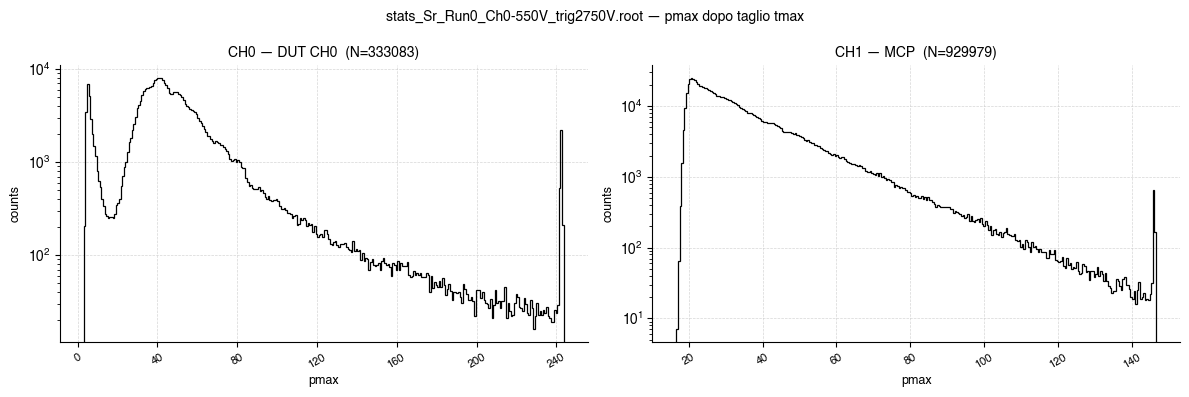

In [283]:
# ── pmax plots filtrati per tmax (intero file) ───────────────────────────────
PMAX_BINS  = 300
PMAX_RANGE = None    # es. (0, 500)   range x di pmax; None = automatico

fig, axes = plt.subplots(1, N_CHANNELS, figsize=(6*N_CHANNELS, 4), squeeze=False)
fig.patch.set_facecolor('white')
fig.suptitle(f"{os.path.basename(ROOT_FILE)} — pmax dopo taglio tmax", fontsize=10, fontweight='bold')
for ch in range(N_CHANNELS):
    ax  = axes[0][ch]
    lbl = 'MCP' if HAS_MCP and ch == MCP_CHANNEL else f'DUT CH{ch}'
    pm  = pmax_all[ch]
    if ch in DUT_CHANNELS:
        t_lo, t_hi = cuts_tmax[ch]
        pm = pm[(tmax_all[ch] >= t_lo) & (tmax_all[ch] <= t_hi)]
    pm = pm[np.isfinite(pm)]
    _style_ax(ax)
    ax.hist(pm, bins=PMAX_BINS, range=PMAX_RANGE, log=True, histtype='step',
            color='black', linewidth=0.9)
    ax.set_title(f"CH{ch} — {lbl}  (N={len(pm)})", fontsize=10)
    ax.set_xlabel("pmax", fontsize=9)
    ax.set_ylabel("counts", fontsize=9)
    ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=8, prune='both'))
    ax.tick_params(axis='x', labelsize=8, rotation=30)
plt.tight_layout()
plt.show()


In [284]:
# ── Taglio pmax (uguale per tutti i batch) ───────────────────────────────────
cuts_pmax = {ch: 10.0 for ch in range(N_CHANNELS)}
cuts_pmax[0] = 20
for ch in range(N_CHANNELS):
    lbl = 'MCP' if HAS_MCP and ch == MCP_CHANNEL else 'DUT'
    print(f"cuts_pmax[{ch}] = {cuts_pmax[ch]}   # CH{ch} – {lbl}")


cuts_pmax[0] = 20   # CH0 – DUT
cuts_pmax[1] = 10.0   # CH1 – MCP


In [285]:
# ── Funzioni di fit (stesse di beta_analyzer) ────────────────────────────────
from scipy.stats import norm as _norm

# ── Opzione fit ───────────────────────────────────────────────────────────────
USE_LANGAUS = True   # True = Langaus (Landau ⊗ Gauss),  False = Moyal

# ── Fit functions ─────────────────────────────────────────────────────────────
def fit_landau(x, amp, mu, sigma):
    return amp * moyal.pdf(x, mu, sigma)

def langaus_pdf(x, mpv, xi, sigma_g):
    """Landau(moyal) ⊗ Gaussian via convoluzione numerica, normalizzata a PDF."""
    span  = 15*xi + 7*sigma_g
    # griglia con numero di punti limitato (evita array enormi -> crash kernel)
    n_pts = int(np.clip(2*span / (0.1*min(xi, sigma_g)), 200, 1500))
    t     = np.linspace(mpv - span, mpv + span, n_pts)
    dx    = t[1] - t[0]
    land  = moyal.pdf(t, mpv, xi)
    xa    = np.atleast_1d(np.asarray(x, dtype=float))
    gauss = _norm.pdf(xa[:, None] - t[None, :], 0, sigma_g)
    return (gauss @ land) * dx

def fit_langaus(x, amp, mpv, xi, sigma_g):
    return amp * langaus_pdf(x, mpv, xi, sigma_g)

def langaus_mode(popt):
    """Moda (picco) della curva Langaus: massimo numerico, raffinato con parabola."""
    _, mpv, xi, sg = popt
    x = np.linspace(mpv - 3*xi - 3*sg, mpv + 3*xi + 3*sg, 801)
    y = langaus_pdf(x, mpv, xi, sg)
    k = int(np.clip(y.argmax(), 1, len(x) - 2))
    d = y[k-1] - 2*y[k] + y[k+1]
    off = float(np.clip(0.5*(y[k-1] - y[k+1]) / d, -1, 1)) if d < 0 else 0.0   # parabola valida solo se è un massimo
    return x[k] + off*(x[1] - x[0])

def langaus_mode_err(popt, pcov):
    """Errore sulla moda per propagazione lineare con la matrice di covarianza completa."""
    popt = np.asarray(popt, float)
    m0   = langaus_mode(popt)
    grad = np.zeros(len(popt))
    for j in range(len(popt)):
        h = 1e-3 * max(abs(popt[j]), 1e-3)
        pp = popt.copy(); pp[j] += h
        grad[j] = (langaus_mode(pp) - m0) / h
    return float(np.sqrt(max(grad @ pcov @ grad, 0.0)))

def fit_gaussian(x, amp, mu, sigma):
    return amp * np.exp(-0.5 * ((x - mu) / sigma)**2)

# ── Wrappers ──────────────────────────────────────────────────────────────────
def do_landau(data, hrange=None):
    if hrange is not None:
        data = data[(data >= hrange[0]) & (data <= hrange[1])]
    counts, edges = np.histogram(data, bins=100, range=hrange)
    centers = 0.5*(edges[:-1] + edges[1:])
    bw = edges[1] - edges[0]
    try:
        if USE_LANGAUS:
            mpv0 = centers[counts.argmax()]
            xi0  = np.std(data) * 0.25
            sg0  = np.std(data) * 0.15
            sd   = np.std(data)
            p0   = [counts.sum()*bw, mpv0, xi0, sg0]
            lo   = [0,      centers[0],  0.01*sd, 0.01*sd]
            hi   = [np.inf, centers[-1], 3*sd,    3*sd]
            popt, pcov = curve_fit(fit_langaus, centers, counts, p0=p0,
                                   bounds=(lo, hi), maxfev=2000)
            mpv, mpv_err = langaus_mode(popt), langaus_mode_err(popt, pcov)
        else:
            p0 = [counts.max(), centers[counts.argmax()], np.std(data)*0.5]
            popt, pcov = curve_fit(fit_landau, centers, counts, p0=p0, maxfev=10000)
            mpv, mpv_err = popt[1], np.sqrt(pcov[1, 1])   # MPV = parametro mu
        return popt, np.sqrt(np.diag(pcov)), counts, edges, mpv, mpv_err
    except Exception:
        npar = 4 if USE_LANGAUS else 3
        return [np.nan]*npar, [np.nan]*npar, counts, edges, np.nan, np.nan

def do_gauss(data, bins=100, hrange=None):
    counts, edges = np.histogram(data, bins=bins, range=hrange)
    centers = 0.5*(edges[:-1] + edges[1:])
    try:
        p0 = [counts.max(), np.mean(data), np.std(data)]
        popt, pcov = curve_fit(fit_gaussian, centers, counts, p0=p0, maxfev=10000)
        return popt, np.sqrt(np.diag(pcov)), counts, edges
    except Exception:
        return [np.nan]*3, [np.nan]*3, counts, edges

In [286]:
# ── Fit per batch ────────────────────────────────────────────────────────────
AREA_RANGE = None        # es. (0, 150)  range di area_new per istogramma e fit
AREA_SENTINEL = 1e6    # |area_new| >= soglia = valore sentinella (es. -1e12), scartato
SHOW_BATCH_FITS = False  # True -> griglia con istogramma + fit di ogni batch

def _event_mask(ch, sl):
    """Maschera tagli (pmax, tmax) per il canale DUT `ch` sugli eventi dello slice."""
    t_lo, t_hi = cuts_tmax[ch]
    tm, pm = tmax_all[ch][sl], pmax_all[ch][sl]
    return (pm > cuts_pmax[ch]) & (tm >= t_lo) & (tm <= t_hi)

batch_rows = []
batch_hist = {ch: [] for ch in DUT_CHANNELS}
for b in range(n_batch):
    s, e = b*BATCH_SIZE, min((b+1)*BATCH_SIZE, n_events)
    sl   = slice(s, e)

    if TIME_MODE == 'file':
        t0, t1 = time_arr[s]/3600, time_arr[e-1]/3600
        t_mid, t_half = 0.5*(t0 + t1), 0.5*(t1 - t0)
    else:
        t_mid, t_half = (b + 0.5)*HOURS_PER_BATCH, 0.5*HOURS_PER_BATCH

    row = {'batch': b, 'n_ev': e - s, 't_h': t_mid, 't_half': t_half}
    for ch in DUT_CHANNELS:
        data = area_all[ch][sl][_event_mask(ch, sl)]
        data = data[np.isfinite(data) & (np.abs(data) < AREA_SENTINEL)]   # via i valori sentinella
        row[f'n{ch}'] = len(data)
        if len(data) >= MIN_EVENTS_FIT:
            popt, perr, counts, edges, mpv, mpv_err = do_landau(data, hrange=AREA_RANGE)
        else:
            popt, perr, counts, edges, mpv, mpv_err = (
                [np.nan]*(4 if USE_LANGAUS else 3), None, None, None, np.nan, np.nan)
        row[f'mpv{ch}']        = mpv
        row[f'mpv{ch}_err']    = mpv_err
        row[f'charge{ch}']     = mpv / CHARGE_DIV
        row[f'charge{ch}_err'] = mpv_err / CHARGE_DIV
        batch_hist[ch].append((counts, edges, popt, mpv))
    batch_rows.append(row)

df_b = pd.DataFrame(batch_rows)
cols = ['batch', 't_h', 'n_ev'] + [c for ch in DUT_CHANNELS for c in (f'n{ch}', f'charge{ch}', f'charge{ch}_err')]
display(df_b[cols].style.format(precision=3))

if SHOW_BATCH_FITS:
    ncols = 6
    for ch in DUT_CHANNELS:
        nrows = int(np.ceil(n_batch / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(3*ncols, 2.6*nrows), squeeze=False)
        fig.suptitle(f"CH{ch} — fit per batch", fontsize=11, fontweight='bold')
        fit_fn = fit_langaus if USE_LANGAUS else fit_landau
        for b, ax in enumerate(axes.ravel()):
            if b >= n_batch:
                ax.axis('off'); continue
            counts, edges, popt, mpv = batch_hist[ch][b]
            _style_ax(ax)
            if counts is None:
                ax.text(0.5, 0.5, 'pochi eventi', transform=ax.transAxes, ha='center', color='red', fontsize=8)
            else:
                ax.stairs(counts, edges, color='black', linewidth=0.8)
                if not np.isnan(popt[0]):
                    xf = np.linspace(edges[0], edges[-1], 400)
                    ax.plot(xf, fit_fn(xf, *popt), color='#3f90da', linewidth=1.0)
                    ax.axvline(mpv, color='#bd1f01', linewidth=0.6, linestyle=':')
            ax.set_title(f"batch {b}", fontsize=8)
            ax.tick_params(labelsize=7)
        plt.tight_layout()
        plt.show()


,batch,t_h,n_ev,n0,charge0,charge0_err
0,0,1.000,30000,9605,5.521,0.020
1,1,3.000,30000,9736,4.634,0.013
2,2,5.000,30000,9906,5.909,0.021
3,3,7.000,30000,9918,5.889,0.016
4,4,9.000,30000,9790,5.964,0.023
5,5,11.000,30000,9805,5.897,0.018
6,6,13.000,30000,9913,5.906,0.018
7,7,15.000,30000,9773,5.869,0.017
8,8,17.000,30000,9998,5.815,0.019
9,9,19.000,30000,9854,5.872,0.020


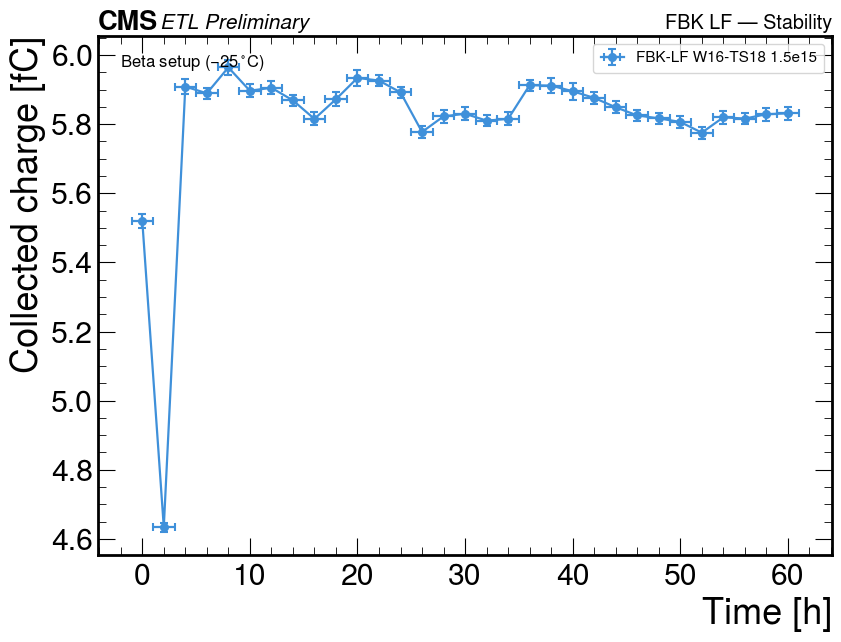

In [287]:
# ── Carica vs tempo ──────────────────────────────────────────────────────────
CHARGE_YLIM = None       # es. (0, 20)
TIME_XLIM   = None       # es. (0, 48)   [h]

def _finish(fig, ax, name, subtitle=None):
    ax.text(0.03, 0.97, SUBTITLE if subtitle is None else subtitle, transform=ax.transAxes, va='top', ha='left', fontsize=12)
    if hep is not None:
        hep.cms.label(label='ETL Preliminary', data=True, rlabel=TITLE, ax=ax, fontsize=15)
    plt.tight_layout()
    if SAVE_IMAGES:
        os.makedirs(SAVE_DIR, exist_ok=True)
        path = f'{SAVE_DIR}/{name}.png'
        fig.savefig(path, dpi=200, bbox_inches='tight')
        print(f'Salvato: {path}')
    plt.show()

# t = 0 al batch START_BATCH; i batch precedenti non vengono plottati
T0_CHARGE = df_b.loc[START_BATCH, 't_h']
df_p = df_b[df_b['batch'] >= START_BATCH]
t_charge = df_p['t_h'] - T0_CHARGE

with (plt.style.context(hep.style.CMS) if hep is not None else plt.style.context('default')):
    for ch in DUT_CHANNELS:
        fig, ax = plt.subplots(figsize=(9, 7))
        ax.errorbar(t_charge, df_p[f'charge{ch}'],
                    xerr=df_p['t_half'], yerr=df_p[f'charge{ch}_err'],
                    color='#3f90da', linestyle='-', marker='o', markersize=5,
                    label=SENSOR_LABELS[CHARGE_SENSOR],
                    linewidth=1.6, capsize=3, markerfacecolor='#3f90da', markeredgewidth=1.5)
        ax.set_xlabel('Time [h]')
        ax.set_ylabel('Collected charge [fC]')
        leg = ax.legend(loc='best', frameon=True, fontsize=11)
        leg.set_draggable(True)
        if CHARGE_YLIM: ax.set_ylim(*CHARGE_YLIM)
        if TIME_XLIM:   ax.set_xlim(*TIME_XLIM)
        _finish(fig, ax, f'charge_vs_time_ch{ch}')


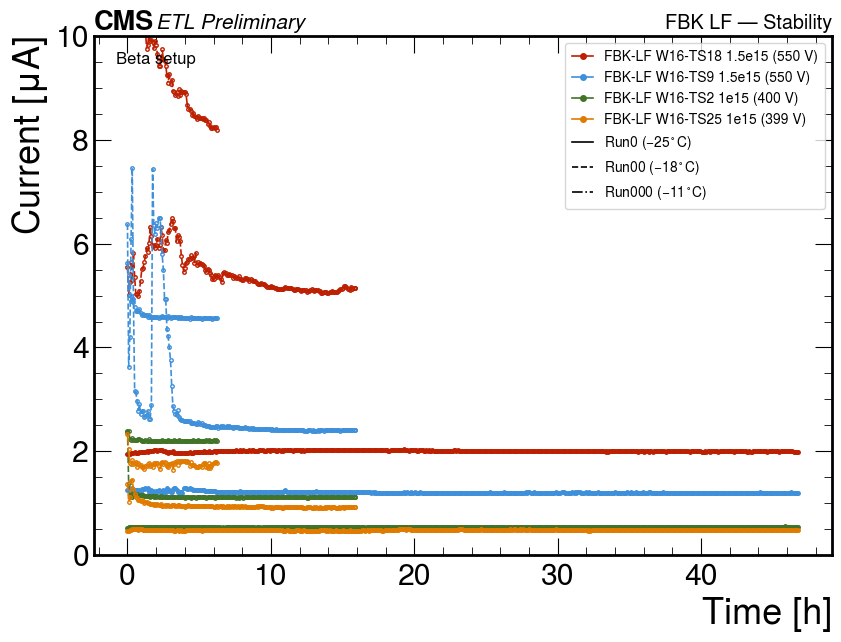

In [288]:
# ── Corrente vs tempo (4 sensori dai .txt, più run insieme) ──────────────────
CURRENT_LOG    = False   # True -> asse y logaritmico
CURRENT_YLIM   = (0,10)    # es. (0, 5)  [uA]
CURRENT_COLORS = ['#bd1f01', '#3f90da', '#417328', '#e07b00']   # colore = sensore
CURRENT_SUBTITLE = "Beta setup"

# Un elemento per run da plottare (rimuovi/commenta una riga per toglierlo).
# t0: tempo assoluto [h] dall'inizio del log del run in cui mettere t = 0
#     (0.0 = inizio del log; i punti prima di t0 non vengono plottati)
CURRENT_RUNS = [
    dict(file=CURRENT_FILE, label=r"Run0 ($-25^\circ$C)", linestyle='-',  hollow=False, t0=0.0),
    dict(file=CURRENT_FILE_NEG18, label=r"Run00 ($-18^\circ$C)", linestyle='--', hollow=True,  t0=0.0),
    dict(file=CURRENT_FILE_NEG11, label=r"Run000 ($-11^\circ$C)", linestyle='-.', hollow=True,  t0=0.0),
]

def _load_current(run):
    df = pd.read_csv(run['file'])
    t  = (df['unix_time'] - df['unix_time'].iloc[0]) / 3600     # [h] dall'inizio del log
    t  = t - float(run['t0'])
    return df[t >= 0], t[t >= 0]

from matplotlib.lines import Line2D
with (plt.style.context(hep.style.CMS) if hep is not None else plt.style.context('default')):
    fig, ax = plt.subplots(figsize=(9, 7))
    sensor_handles = {}
    for run in CURRENT_RUNS:
        df_i, t_i = _load_current(run)
        for k in range(4):
            col = CURRENT_COLORS[k]
            ln, = ax.plot(t_i, df_i[f'I{k}[uA]'], color=col, linestyle=run['linestyle'],
                          marker='o', markersize=2.5, linewidth=1.2,
                          markerfacecolor='none' if run['hollow'] else col)
            sensor_handles.setdefault(k, Line2D([], [], color=col, linestyle='-', marker='o',
                markersize=4, linewidth=1.2,
                label=f"{SENSOR_LABELS[k]} ({df_i[f'V{k}[V]'].median():.0f} V)"))
    run_handles = [Line2D([], [], color='black', linestyle=r['linestyle'], linewidth=1.2,
                          label=r['label']) for r in CURRENT_RUNS]
    ax.set_xlabel('Time [h]')
    ax.set_ylabel(r'Current [$\mu$A]')
    if CURRENT_LOG:  ax.set_yscale('log')
    if CURRENT_YLIM: ax.set_ylim(*CURRENT_YLIM)
    if TIME_XLIM:    ax.set_xlim(*TIME_XLIM)
    leg = ax.legend(handles=list(sensor_handles.values()) + run_handles,
                    loc='best', frameon=True, fontsize=10)
    leg.set_draggable(True)
    _finish(fig, ax, 'current_vs_time', subtitle=CURRENT_SUBTITLE)


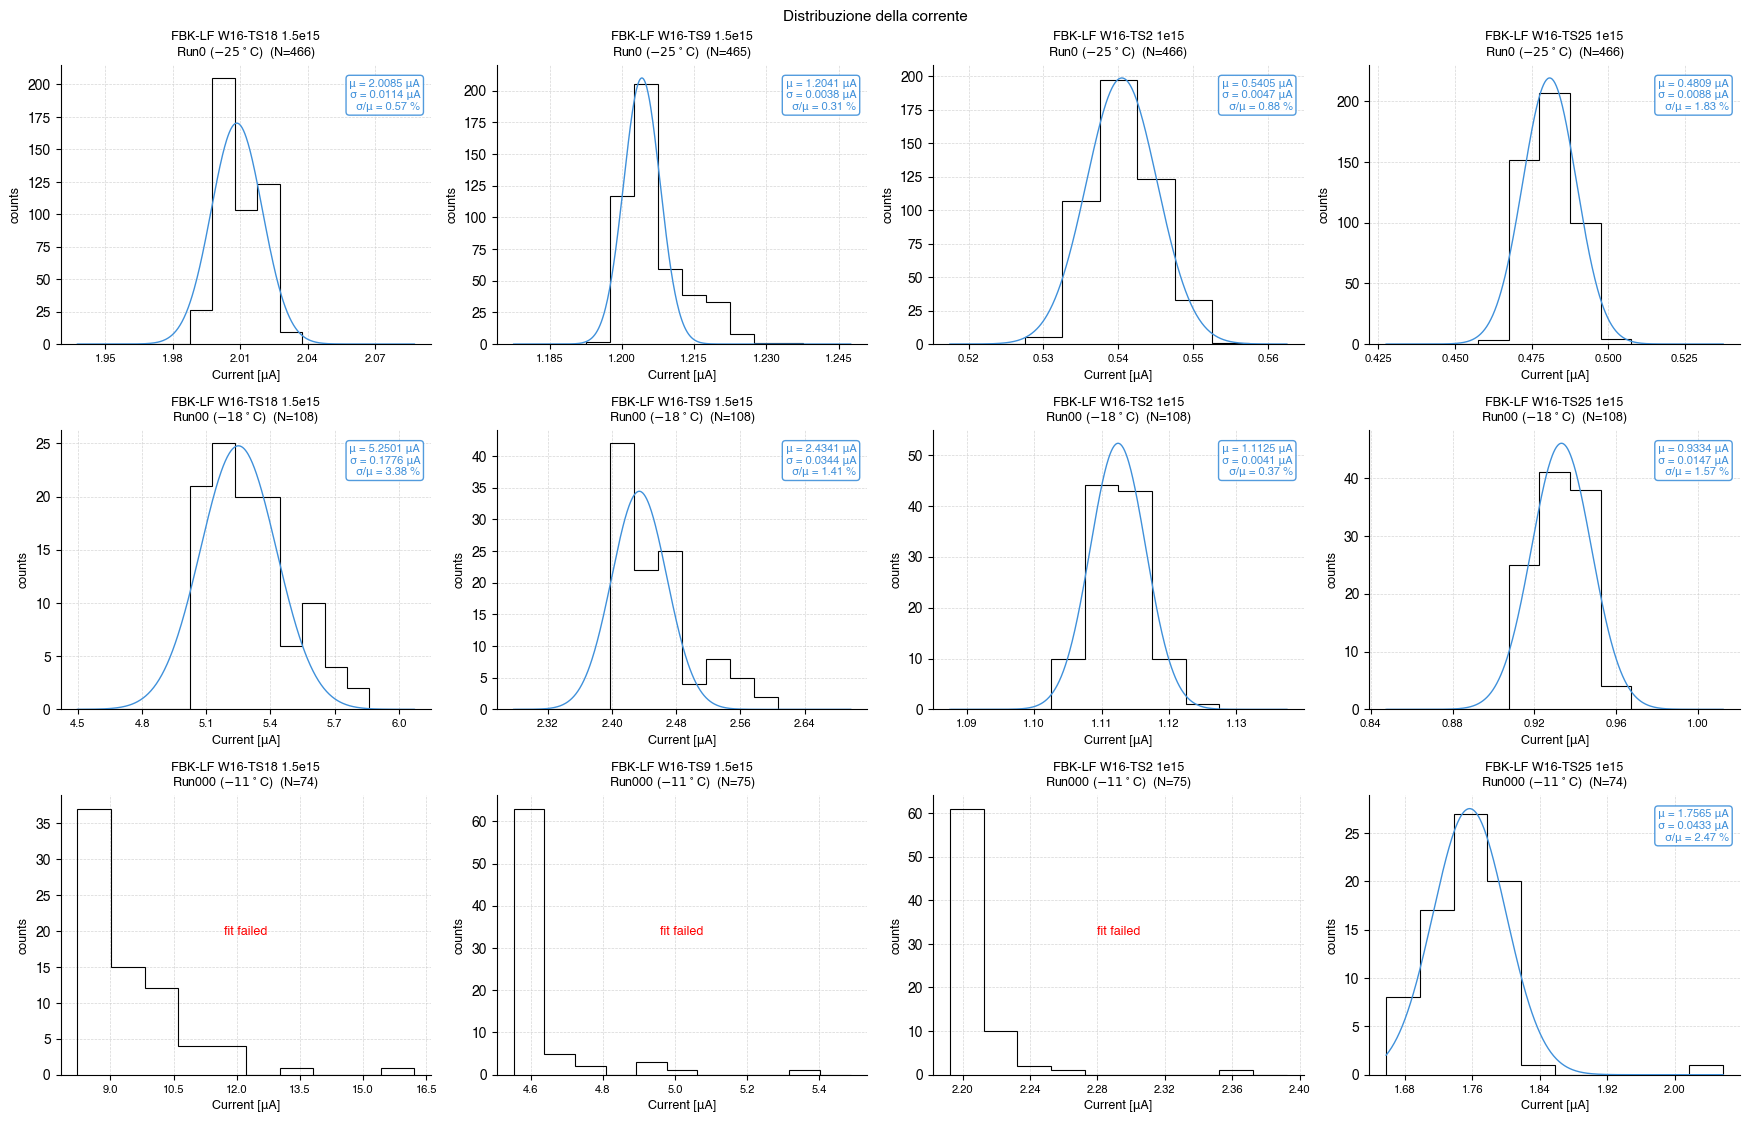

,run,sensor,N,mu [uA],sigma [uA]
0,Run0 ($-25^\circ$C),FBK-LF W16-TS18 1.5e15,466,2.0085,0.0114
1,Run0 ($-25^\circ$C),FBK-LF W16-TS9 1.5e15,465,1.2041,0.0038
2,Run0 ($-25^\circ$C),FBK-LF W16-TS2 1e15,466,0.5405,0.0047
3,Run0 ($-25^\circ$C),FBK-LF W16-TS25 1e15,466,0.4809,0.0088
4,Run00 ($-18^\circ$C),FBK-LF W16-TS18 1.5e15,108,5.2501,0.1776
5,Run00 ($-18^\circ$C),FBK-LF W16-TS9 1.5e15,108,2.4341,0.0344
6,Run00 ($-18^\circ$C),FBK-LF W16-TS2 1e15,108,1.1125,0.0041
7,Run00 ($-18^\circ$C),FBK-LF W16-TS25 1e15,108,0.9334,0.0147
8,Run000 ($-11^\circ$C),FBK-LF W16-TS18 1.5e15,74,nan,nan
9,Run000 ($-11^\circ$C),FBK-LF W16-TS9 1.5e15,75,nan,nan


In [290]:
# ── Istogrammi della corrente per sensore / misura + fit gaussiano ───────────
HIST_RANGE_PCT = (1, 99)   # percentili per il range dell'istogramma (taglia i picchi); None = tutto
                               # (ignorato nei pannelli dove xrange è impostato)

# ── Impostazioni di OGNI istogramma: chiave = (run, sensore) ─────────────────
# run    = indice in CURRENT_RUNS (0 = Run0, 1 = Run00, 2 = Run000)       sensore = canale HV 0..3
#   bins   : numero massimo di bin (la larghezza è multiplo della risoluzione, es. 0.005 uA)
#   xrange : (x_min, x_max) in uA per istogramma, fit e asse;  None = automatico (percentili)
#   trange : finestra temporale (t_min, t_max) in ore dopo il t0 di CURRENT_RUNS; None = tutto,
#            un estremo None = nessun limite da quel lato, es. (4, None)
HIST_DEFAULT = dict(bins=10, xrange=None, trange=None)     # usato se un pannello non è elencato
HIST_CFG = {
    # ── Run0 ──
    (0, 0): dict(bins=20, xrange=(1.94,2.08), trange=(8,None)),       # TS18 1.5e15
    (0, 1): dict(bins=20, xrange=(1.18,1.24), trange=(8,None)),       # TS9  1.5e15
    (0, 2): dict(bins=20, xrange=(0.52,0.56), trange=(8,None)),       # TS2  1e15
    (0, 3): dict(bins=20, xrange=(0.43,0.53), trange=(8,None)),       # TS25 1e15
    # ── Run00 ──
    (1, 0): dict(bins=15, xrange=(4.5,6), trange=(4,13)),  # TS18 1.5e15
    (1, 1): dict(bins=15, xrange=(2.28,2.68), trange=(4,13)),  # TS9  1.5e15
    (1, 2): dict(bins=15, xrange=(1.09,1.13), trange=(4,13)),  # TS2  1e15
    (1, 3): dict(bins=15, xrange=(0.85,1), trange=(4,13)),  # TS25 1e15
    # ── Run000 ──
    (2, 0): dict(bins=10, xrange=None, trange=None),       # TS18 1.5e15
    (2, 1): dict(bins=10, xrange=None, trange=None),       # TS9  1.5e15
    (2, 2): dict(bins=10, xrange=None, trange=None),       # TS2  1e15
    (2, 3): dict(bins=10, xrange=None, trange=None),       # TS25 1e15
}

def _cfg(r, k):
    return {**HIST_DEFAULT, **HIST_CFG.get((r, k), {})}

def _hist_current(vals, bins, xrange=None):
    """Istogramma con bin allineati alla risoluzione della misura (es. 0.005 uA)."""
    vals = np.asarray(vals, float)
    if xrange:
        vals = vals[(vals >= xrange[0]) & (vals <= xrange[1])]
    elif HIST_RANGE_PCT:
        lo, hi = np.percentile(vals, HIST_RANGE_PCT)
        vals = vals[(vals >= lo) & (vals <= hi)]
    if len(vals) < 3:
        return vals, None, None
    u    = np.unique(vals)
    res  = np.min(np.diff(u)) if len(u) > 1 else 1e-3
    lo, hi = xrange if xrange else (vals.min(), vals.max())
    w    = res * max(1, int(np.ceil((hi - lo) / bins / res)))
    start = round(lo / res) * res - res/2                  # gli edge stanno tra due livelli ADC
    edges = np.arange(start, hi + res/2 + w, w)
    counts, edges = np.histogram(vals, bins=edges)
    return vals, counts, edges

def _fit_gauss_hist(counts, edges, vals):
    centers = 0.5*(edges[:-1] + edges[1:])
    try:
        p0 = [counts.max(), np.mean(vals), max(np.std(vals), 1e-6)]
        popt, _ = curve_fit(fit_gaussian, centers, counts, p0=p0, maxfev=10000)
        popt[2] = abs(popt[2])
        return popt
    except Exception:
        return None

nruns = len(CURRENT_RUNS)
fig, axes = plt.subplots(nruns, 4, figsize=(4.4*4, 3.8*nruns), squeeze=False)
fig.patch.set_facecolor('white')
fig.suptitle("Distribuzione della corrente", fontsize=11, fontweight='bold')

hist_rows = []
for r, run in enumerate(CURRENT_RUNS):
    df_run, t_run = _load_current(run)
    for k in range(4):
        ax  = axes[r][k]
        cfg = _cfg(r, k)
        df_i, win = df_run, cfg['trange']
        if win:
            m = np.ones(len(t_run), bool)
            if win[0] is not None: m &= (t_run >= win[0]).values
            if win[1] is not None: m &= (t_run <= win[1]).values
            df_i = df_run[m]
        vals, counts, edges = _hist_current(df_i[f'I{k}[uA]'].values, cfg['bins'], cfg['xrange'])
        _style_ax(ax)
        if counts is None:
            ax.text(0.5, 0.5, 'pochi dati nella finestra', transform=ax.transAxes,
                    ha='center', color='red', fontsize=9)
            ax.set_title(f"{SENSOR_LABELS[k]}\n{run['label']}  (N={len(vals)})", fontsize=9)
            hist_rows.append({'run': run['label'], 'sensor': SENSOR_LABELS[k], 'N': len(vals),
                              'mu [uA]': np.nan, 'sigma [uA]': np.nan})
            continue
        popt = _fit_gauss_hist(counts, edges, vals)
        ax.stairs(counts, edges, color='black', linewidth=0.8, zorder=2)
        if popt is not None:
            xf = np.linspace(edges[0], edges[-1], 500)
            ax.plot(xf, fit_gaussian(xf, *popt), color='#3f90da', linewidth=1.0, zorder=4)
            ax.text(0.97, 0.95,
                    f"μ = {popt[1]:.4f} μA\nσ = {popt[2]:.4f} μA\nσ/μ = {100*popt[2]/popt[1]:.2f} %",
                    transform=ax.transAxes, ha='right', va='top', fontsize=8, color='#3f90da',
                    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#3f90da', alpha=0.9))
        else:
            ax.text(0.5, 0.5, 'fit failed', transform=ax.transAxes, ha='center', color='red', fontsize=9)
        ax.set_title(f"{SENSOR_LABELS[k]}\n{run['label']}  (N={len(vals)})", fontsize=9)
        ax.set_xlabel("Current [μA]", fontsize=9)
        ax.set_ylabel("counts", fontsize=9)
        ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=6, prune='both'))
        ax.tick_params(axis='x', labelsize=8)
        hist_rows.append({'run': run['label'], 'sensor': SENSOR_LABELS[k], 'N': len(vals),
                          'mu [uA]':    popt[1] if popt is not None else np.nan,
                          'sigma [uA]': popt[2] if popt is not None else np.nan})
plt.tight_layout()
if SAVE_IMAGES:
    os.makedirs(SAVE_DIR, exist_ok=True)
    fig.savefig(f'{SAVE_DIR}/current_hist.png', dpi=200, bbox_inches='tight')
    print(f'Salvato: {SAVE_DIR}/current_hist.png')
plt.show()

display(pd.DataFrame(hist_rows).style.format(precision=4))
